<a href="https://colab.research.google.com/github/divineredie-bot/kion-recommender-system/blob/main/kion_recommender.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!git clone https://github.com/irsafilo/KION_DATASET.git

import os

for root, dirs, files in os.walk("/content/KION_DATASET"):
    level = root.replace("/content/KION_DATASET", "").count(os.sep)
    if level > 2:
        dirs[:] = []
        continue
    print("  " * level + os.path.basename(root) + "/")
    for file in files:
        print("  " * (level + 1) + file)

Cloning into 'KION_DATASET'...
remote: Enumerating objects: 129, done.
remote: Counting objects: 100% (115/115), done.
remote: Compressing objects: 100% (114/114), done.
remote: Total 129 (delta 66), reused 10 (delta 1), pack-reused 14 (from 1)
Receiving objects: 100% (129/129), 194.05 MiB | 33.69 MiB/s, done.
Resolving deltas: 100% (67/67), done.
Updating files: 100% (9/9), done.
KION_DATASET/
  README.md
  interactions.csv.zip
  sample_submission.csv
  data_en.zip
  data_original.zip
  data_en/
    items_en.csv
    users_en.csv
  data_original/
    users.csv
    items.csv
  .git/
    config
    index
    description
    HEAD
    packed-refs
    objects/
    info/
      exclude
    logs/
      HEAD
    hooks/
      commit-msg.sample
      pre-receive.sample
      pre-rebase.sample
      post-update.sample
      update.sample
      pre-commit.sample
      sendemail-validate.sample
      pre-applypatch.sample
      push-to-checkout.sample
      pre-push.sample
      applypatch-msg.sampl

In [3]:
import zipfile
from pathlib import Path

base = Path("/content/KION_DATASET")

for name in ["interactions.csv.zip", "data_en.zip"]:
    with zipfile.ZipFile(base / name, "r") as z:
        z.extractall(base)

print("Распаковка завершена!")

for path in base.rglob("*.csv"):
    print(path.relative_to(base), "—", round(path.stat().st_size / 1024**2, 2), "МБ")

Распаковка завершена!
sample_submission.csv — 13.44 МБ
interactions.csv — 50.0 МБ
data_en/items_en.csv — 14.73 МБ
data_en/users_en.csv — 32.47 МБ
data_en/interactions.csv — 171.69 МБ
data_original/users.csv — 28.56 МБ
data_original/items.csv — 30.36 МБ
__MACOSX/data_en/._interactions.csv — 0.0 МБ
__MACOSX/data_en/._users_en.csv — 0.0 МБ
__MACOSX/data_en/._items_en.csv — 0.0 МБ


In [4]:
import pandas as pd

base = "/content/KION_DATASET"

# Загружаем таблицу взаимодействий
interactions = pd.read_csv(
    f"{base}/interactions.csv",
    nrows=5
)

# Загружаем информацию о фильмах
items = pd.read_csv(f"{base}/data_en/items_en.csv", nrows=5)

# Загружаем информацию о пользователях
users = pd.read_csv(f"{base}/data_en/users_en.csv", nrows=5)

print("=== ВЗАИМОДЕЙСТВИЯ ===")
print(interactions.columns.tolist())
print(interactions.head())

print("\n=== ФИЛЬМЫ ===")
print(items.columns.tolist())
print(items.head())

print("\n=== ПОЛЬЗОВАТЕЛИ ===")
print(users.columns.tolist())
print(users.head())

=== ВЗАИМОДЕЙСТВИЯ ===
['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct']
   user_id  item_id last_watch_dt  total_dur  watched_pct
0   176549     9506    2021-05-11       4250         72.0
1   699317     1659    2021-05-29       8317        100.0
2   656683     7107    2021-05-09         10          0.0
3   864613     7638    2021-07-05      14483        100.0
4   964868     9506    2021-04-30       6725        100.0

=== ФИЛЬМЫ ===
['Unnamed: 0', 'item_id', 'content_type', 'title', 'title_orig', 'release_year', 'genres', 'countries', 'for_kids', 'age_rating', 'studios', 'description', 'keywords', 'actors_translated', 'actors_transliterated', 'directors_translated', 'transliterated']
   Unnamed: 0  item_id content_type                          title  \
0           0    10711         film                    Talk to her   
1           1     2508         film                  Naked Peppers   
2           2    10716         film                 Tactical force   
3        

In [5]:
import pandas as pd

base = "/content/KION_DATASET"

for name in ["interactions.csv", "data_en/interactions.csv"]:
    path = f"{base}/{name}"

    print(f"\n=== {name} ===")

    df = pd.read_csv(path, nrows=5)

    print("Столбцы:", df.columns.tolist())
    print(df.head().to_string(index=False))


=== interactions.csv ===
Столбцы: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct']
 user_id  item_id last_watch_dt  total_dur  watched_pct
  176549     9506    2021-05-11       4250         72.0
  699317     1659    2021-05-29       8317        100.0
  656683     7107    2021-05-09         10          0.0
  864613     7638    2021-07-05      14483        100.0
  964868     9506    2021-04-30       6725        100.0

=== data_en/interactions.csv ===
Столбцы: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct']
 user_id  item_id last_watch_dt  total_dur  watched_pct
  176549     9506    2021-05-11       4250         72.0
  699317     1659    2021-05-29       8317        100.0
  656683     7107    2021-05-09         10          0.0
  864613     7638    2021-07-05      14483        100.0
  964868     9506    2021-04-30       6725        100.0


In [6]:
import pandas as pd
import numpy as np

path = "/content/KION_DATASET/interactions.csv"

df = pd.read_csv(path, parse_dates=["last_watch_dt"])

# Цель: просмотрено не менее 50% контента
df["target"] = (df["watched_pct"] >= 50).astype("int8")

print("Размер таблицы:", df.shape)
print("Период:", df["last_watch_dt"].min(), "—", df["last_watch_dt"].max())
print("\nПропуски:")
print(df.isna().sum())
print("\nБаланс целевого класса:")
print(df["target"].value_counts())
print("\nДоля положительных взаимодействий:")
print(round(df["target"].mean() * 100, 2), "%")
print("\nПримеры:")
print(df.head())

Размер таблицы: (1594787, 6)
Период: 20 — 2021-08-22

Пропуски:
user_id            0
item_id            0
last_watch_dt      0
total_dur          1
watched_pct      268
target             0
dtype: int64

Баланс целевого класса:
target
0    890869
1    703918
Name: count, dtype: int64

Доля положительных взаимодействий:
44.14 %

Примеры:
   user_id  item_id last_watch_dt  total_dur  watched_pct  target
0   176549     9506    2021-05-11     4250.0         72.0       1
1   699317     1659    2021-05-29     8317.0        100.0       1
2   656683     7107    2021-05-09       10.0          0.0       0
3   864613     7638    2021-07-05    14483.0        100.0       1
4   964868     9506    2021-04-30     6725.0        100.0       1


In [7]:
print("Тип даты:", df["last_watch_dt"].dtype)
print("Первые даты:")
print(df["last_watch_dt"].head(10).to_list())

print("\nКоличество строк:", len(df))
print("Количество пользователей:", df["user_id"].nunique())
print("Количество фильмов:", df["item_id"].nunique())

print("\nРаспределение по датам:")
print(df["last_watch_dt"].dt.to_period("M").value_counts().sort_index())

Тип даты: object
Первые даты:
['2021-05-11', '2021-05-29', '2021-05-09', '2021-07-05', '2021-04-30', '2021-05-13', '2021-08-14', '2021-08-04', '2021-06-13', '2021-08-22']

Количество строк: 1594787
Количество пользователей: 567588
Количество фильмов: 12693

Распределение по датам:


AttributeError: Can only use .dt accessor with datetimelike values

In [8]:
df["last_watch_dt"] = pd.to_datetime(df["last_watch_dt"], errors="coerce")

print("Тип даты:", df["last_watch_dt"].dtype)
print("Ошибочных дат:", df["last_watch_dt"].isna().sum())

print("\nРаспределение по месяцам:")
print(
    df["last_watch_dt"]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

print("\nПользователей:", df["user_id"].nunique())
print("Фильмов:", df["item_id"].nunique())

Тип даты: datetime64[ns]
Ошибочных дат: 1

Распределение по месяцам:
last_watch_dt
2021-03     77213
2021-04    149717
2021-05    221713
2021-06    348872
2021-07    427045
2021-08    370226
Freq: M, Name: count, dtype: int64

Пользователей: 567588
Фильмов: 12693


In [9]:
# Удаляем строки без даты
df = df.dropna(subset=["last_watch_dt"]).copy()

# Сортируем взаимодействия по времени
df = df.sort_values("last_watch_dt").reset_index(drop=True)

# Первые 80% — обучение, следующие 20% — тест
split_idx = int(len(df) * 0.8)

train = df.iloc[:split_idx].copy()
test = df.iloc[split_idx:].copy()

print("Обучение:", train.shape)
print("Тест:", test.shape)
print("Период обучения:", train["last_watch_dt"].min(), "—", train["last_watch_dt"].max())
print("Период теста:", test["last_watch_dt"].min(), "—", test["last_watch_dt"].max())

print("\nДоля положительных примеров:")
print("Обучение:", round(train["target"].mean(), 3))
print("Тест:", round(test["target"].mean(), 3))

Обучение: (1275828, 6)
Тест: (318958, 6)
Период обучения: 2021-03-13 00:00:00 — 2021-08-04 00:00:00
Период теста: 2021-08-04 00:00:00 — 2021-08-22 00:00:00

Доля положительных примеров:
Обучение: 0.461
Тест: 0.364


In [10]:
from sklearn.metrics import roc_auc_score, log_loss
import numpy as np

# Простая базовая модель: вероятность положительного просмотра
# равна доле положительных примеров в обучении
baseline_prob = np.full(len(test), train["target"].mean())

print("Baseline ROC-AUC:", round(roc_auc_score(test["target"], baseline_prob), 4))
print("Baseline LogLoss:", round(log_loss(test["target"], baseline_prob), 4))

Baseline ROC-AUC: 0.5
Baseline LogLoss: 0.6749


In [11]:
from sklearn.metrics import roc_auc_score, log_loss
from sklearn.ensemble import HistGradientBoostingClassifier

# Статистики только по обучающим данным
user_stats = train.groupby("user_id").agg(
    user_interactions=("item_id", "count"),
    user_positive_rate=("target", "mean")
)

item_stats = train.groupby("item_id").agg(
    item_interactions=("user_id", "count"),
    item_positive_rate=("target", "mean")
)

# Присоединяем статистики к обучению и тесту
def make_features(data):
    result = data[["user_id", "item_id"]].copy()

    result = result.join(user_stats, on="user_id")
    result = result.join(item_stats, on="item_id")

    result["user_interactions"] = result["user_interactions"].fillna(0)
    result["user_positive_rate"] = result["user_positive_rate"].fillna(train["target"].mean())
    result["item_interactions"] = result["item_interactions"].fillna(0)
    result["item_positive_rate"] = result["item_positive_rate"].fillna(train["target"].mean())

    return result[[
        "user_interactions",
        "user_positive_rate",
        "item_interactions",
        "item_positive_rate"
    ]]

X_train = make_features(train)
X_test = make_features(test)

y_train = train["target"]
y_test = test["target"]

print("Признаки обучения:", X_train.shape)
print("Признаки теста:", X_test.shape)

model = HistGradientBoostingClassifier(
    max_iter=100,
    max_leaf_nodes=15,
    learning_rate=0.1,
    random_state=42
)

model.fit(X_train, y_train)

pred = model.predict_proba(X_test)[:, 1]

print("\nGradient Boosting ROC-AUC:", round(roc_auc_score(y_test, pred), 4))
print("Gradient Boosting LogLoss:", round(log_loss(y_test, pred), 4))

Признаки обучения: (1275828, 4)
Признаки теста: (318958, 4)

Gradient Boosting ROC-AUC: 0.5683
Gradient Boosting LogLoss: 2.2691


In [12]:
print("Минимальная вероятность:", pred.min())
print("Максимальная вероятность:", pred.max())
print("Средняя вероятность:", pred.mean())

print("\nРаспределение вероятностей:")
print(pd.Series(pred).describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]))

print("\nСредняя доля положительных примеров в тесте:", round(y_test.mean(), 4))

Минимальная вероятность: 2.0505819075752357e-05
Максимальная вероятность: 0.9999739673829555
Средняя вероятность: 0.7003178122560655

Распределение вероятностей:
count    318958.000000
mean          0.700318
std           0.372863
min           0.000021
1%            0.000021
10%           0.000021
50%           0.958223
90%           0.995253
99%           0.999974
max           0.999974
dtype: float64

Средняя доля положительных примеров в тесте: 0.3644


In [13]:
from sklearn.metrics import log_loss, roc_auc_score

print("Доля положительных в обучении:", round(y_train.mean(), 4))
print("Доля положительных в тесте:", round(y_test.mean(), 4))
print("Средняя вероятность модели:", round(pred.mean(), 4))

print("LogLoss модели:", round(log_loss(y_test, pred), 4))
print("LogLoss baseline:", round(log_loss(
    y_test,
    np.full(len(y_test), y_train.mean())
), 4))

Доля положительных в обучении: 0.4606
Доля положительных в тесте: 0.3644
Средняя вероятность модели: 0.7003
LogLoss модели: 2.2691
LogLoss baseline: 0.6749


In [14]:

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss
import pandas as pd
import numpy as np

# Убедимся, что записи отсортированы по времени
data = df.dropna(subset=["last_watch_dt", "watched_pct"]).copy()
data = data.sort_values("last_watch_dt").reset_index(drop=True)
data["target"] = (data["watched_pct"] >= 50).astype("int8")

# Хронологическое разделение 60% / 20% / 20%
n = len(data)
cut1 = int(n * 0.60)
cut2 = int(n * 0.80)

history = data.iloc[:cut1].copy()
train_new = data.iloc[cut1:cut2].copy()
test_new = data.iloc[cut2:].copy()

# Статистики считаем только на историческом периоде
user_stats = history.groupby("user_id")["target"].agg(["size", "mean"])
item_stats = history.groupby("item_id")["target"].agg(["size", "mean"])
global_rate = history["target"].mean()

def make_features(part):
    return pd.DataFrame({
        "user_interactions": part["user_id"].map(
            user_stats["size"]
        ).fillna(0).astype("float32"),
        "user_positive_rate": part["user_id"].map(
            user_stats["mean"]
        ).fillna(global_rate).astype("float32"),
        "item_interactions": part["item_id"].map(
            item_stats["size"]
        ).fillna(0).astype("float32"),
        "item_positive_rate": part["item_id"].map(
            item_stats["mean"]
        ).fillna(global_rate).astype("float32"),
    }, index=part.index)

X_train_new = make_features(train_new)
X_test_new = make_features(test_new)
y_train_new = train_new["target"]
y_test_new = test_new["target"]

model_new = HistGradientBoostingClassifier(
    max_iter=100,
    max_leaf_nodes=15,
    learning_rate=0.1,
    random_state=42
)

model_new.fit(X_train_new, y_train_new)
pred_new = model_new.predict_proba(X_test_new)[:, 1]

baseline_new = np.full(len(y_test_new), y_train_new.mean())

print("Размер истории:", len(history))
print("Размер обучения:", len(train_new))
print("Размер теста:", len(test_new))
print("Доля положительных в тесте:", round(y_test_new.mean(), 4))
print("Средняя вероятность модели:", round(pred_new.mean(), 4))
print("Baseline ROC-AUC:", round(
    roc_auc_score(y_test_new, baseline_new), 4
))
print("Model ROC-AUC:", round(
    roc_auc_score(y_test_new, pred_new), 4
))
print("Baseline LogLoss:", round(
    log_loss(y_test_new, baseline_new), 4
))
print("Model LogLoss:", round(
    log_loss(y_test_new, pred_new), 4
))


Размер истории: 956711
Размер обучения: 318904
Размер теста: 318904
Доля положительных в тесте: 0.3644
Средняя вероятность модели: 0.3983
Baseline ROC-AUC: 0.5
Model ROC-AUC: 0.6676
Baseline LogLoss: 0.6613
Model LogLoss: 0.6182


In [15]:
results = pd.DataFrame([
    {
        "model": "Baseline",
        "ROC-AUC": roc_auc_score(y_test_new, baseline_new),
        "LogLoss": log_loss(y_test_new, baseline_new)
    },
    {
        "model": "HistGradientBoosting",
        "ROC-AUC": roc_auc_score(y_test_new, pred_new),
        "LogLoss": log_loss(y_test_new, pred_new)
    }
])

results.round(4)

,model,ROC-AUC,LogLoss
0,Baseline,0.5000,0.6613
1,HistGradientBoosting,0.6676,0.6182


In [16]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score, log_loss

lr_model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=300, random_state=42)
)

lr_model.fit(X_train_new, y_train_new)
lr_pred = lr_model.predict_proba(X_test_new)[:, 1]

print("Logistic Regression ROC-AUC:",
      round(roc_auc_score(y_test_new, lr_pred), 4))
print("Logistic Regression LogLoss:",
      round(log_loss(y_test_new, lr_pred), 4))

Logistic Regression ROC-AUC: 0.6555
Logistic Regression LogLoss: 0.6244


In [17]:
results = pd.DataFrame([
    {
        "model": "Baseline",
        "ROC-AUC": roc_auc_score(y_test_new, baseline_new),
        "LogLoss": log_loss(y_test_new, baseline_new)
    },
    {
        "model": "Logistic Regression",
        "ROC-AUC": roc_auc_score(y_test_new, lr_pred),
        "LogLoss": log_loss(y_test_new, lr_pred)
    },
    {
        "model": "HistGradientBoosting",
        "ROC-AUC": roc_auc_score(y_test_new, pred_new),
        "LogLoss": log_loss(y_test_new, pred_new)
    }
])

results = results.round(4)
display(results)

,model,ROC-AUC,LogLoss
0,Baseline,0.5000,0.6613
1,Logistic Regression,0.6555,0.6244
2,HistGradientBoosting,0.6676,0.6182


In [18]:
from sklearn.metrics import ndcg_score

# NDCG оценивает, насколько высоко модель ставит
# положительные примеры внутри тестовой выборки.
k = 10
ndcg = ndcg_score(
    y_test_new.to_numpy().reshape(1, -1),
    pred_new.reshape(1, -1),
    k=k
)

print(f"NDCG@{k}: {ndcg:.4f}")

NDCG@10: 0.8643


In [19]:
eval_df = test_new[["user_id", "item_id", "target"]].copy()
eval_df["score"] = pred_new

# Сколько пользователей имеют положительные примеры в тесте?
positive_users = eval_df.groupby("user_id")["target"].sum()
eligible_users = positive_users[positive_users > 0].index

print("Пользователей в тесте:", eval_df["user_id"].nunique())
print("Пользователей с положительными примерами:", len(eligible_users))

Пользователей в тесте: 167761
Пользователей с положительными примерами: 74938


In [21]:

import numpy as np
from sklearn.metrics import ndcg_score

ndcg_values = []
recall_values = []
skipped = 0

for user_id, group in eval_df.groupby("user_id", sort=False):
    y = group["target"].to_numpy()
    scores = group["score"].to_numpy()

    # Для ранжирования нужны хотя бы два фильма
    if len(group) < 2 or y.sum() == 0:
        skipped += 1
        continue

    order = np.argsort(-scores)
    top_k = order[:10]

    recall_values.append(y[top_k].sum() / y.sum())
    ndcg_values.append(
        ndcg_score(
            y.reshape(1, -1),
            scores.reshape(1, -1),
            k=10
        )
    )

print("Пользователей оценено:", len(ndcg_values))
print("Пользователей пропущено:", skipped)
print("Personal NDCG@10:", round(float(np.mean(ndcg_values)), 4))
print("Personal Recall@10:", round(float(np.mean(recall_values)), 4))


Пользователей оценено: 42487
Пользователей пропущено: 125274
Personal NDCG@10: 0.8733
Personal Recall@10: 0.9957


In [22]:

user_test_counts = eval_df.groupby("user_id").agg(
    test_items=("item_id", "count"),
    positives=("target", "sum")
)

print("Фильмов на пользователя в тесте:")
print(user_test_counts["test_items"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]
))

print("\nПоложительных фильмов на пользователя:")
print(user_test_counts["positives"].describe(
    percentiles=[0.5, 0.75, 0.9, 0.99]
))


Фильмов на пользователя в тесте:
count    167761.000000
mean          1.900942
std           1.855108
min           1.000000
25%           1.000000
50%           1.000000
75%           2.000000
90%           4.000000
99%           9.000000
max          81.000000
Name: test_items, dtype: float64

Положительных фильмов на пользователя:
count    167761.000000
mean          0.692610
std           1.135688
min           0.000000
50%           0.000000
75%           1.000000
90%           2.000000
99%           5.000000
max          30.000000
Name: positives, dtype: float64


In [23]:

print("Уникальных фильмов во всём датасете:", data["item_id"].nunique())
print("Фильмов в историческом периоде:", history["item_id"].nunique())
print("Фильмов в тесте:", test_new["item_id"].nunique())

known_items = set(history["item_id"])
test_items = set(test_new["item_id"])

print(
    "Фильмов теста, уже известных по истории:",
    len(test_items & known_items)
)
print(
    "Новых для истории фильмов в тесте:",
    len(test_items - known_items)
)


Уникальных фильмов во всём датасете: 12639
Фильмов в историческом периоде: 11543
Фильмов в тесте: 6907
Фильмов теста, уже известных по истории: 6125
Новых для истории фильмов в тесте: 782


In [24]:

# Уникальные фильмы в тесте
test_catalog = set(test_new["item_id"].unique())

# Фильмы, для которых есть историческая статистика
known_catalog = set(item_stats.index)

known_test = test_catalog & known_catalog
unknown_test = test_catalog - known_catalog

print("Фильмов в тестовом каталоге:", len(test_catalog))
print("Фильмов с историей:", len(known_test))
print("Фильмов без истории:", len(unknown_test))
print(
    "Доля фильмов без истории:",
    round(len(unknown_test) / len(test_catalog) * 100, 2),
    "%"
)


Фильмов в тестовом каталоге: 6907
Фильмов с историей: 6125
Фильмов без истории: 782
Доля фильмов без истории: 11.32 %


In [25]:
# Проверяем холодный старт на уровне взаимодействий
test_with_history = test_new["item_id"].isin(item_stats.index)

print("Взаимодействий в тесте:", len(test_new))
print(
    "Взаимодействий с известными фильмами:",
    int(test_with_history.sum())
)
print(
    "Взаимодействий с неизвестными фильмами:",
    int((~test_with_history).sum())
)
print(
    "Доля взаимодействий с неизвестными фильмами:",
    round((~test_with_history).mean() * 100, 2), "%"
)

Взаимодействий в тесте: 318904
Взаимодействий с известными фильмами: 279754
Взаимодействий с неизвестными фильмами: 39150
Доля взаимодействий с неизвестными фильмами: 12.28 %


In [26]:

from sklearn.metrics import roc_auc_score, log_loss
import pandas as pd

test_known = test_new["item_id"].isin(item_stats.index).to_numpy()
y_test_array = y_test_new.to_numpy()

def evaluate_group(name, mask):
    y = y_test_array[mask]
    p = pred_new[mask]

    print(f"\n{name}")
    print("Количество:", len(y))

    if len(y) == 0 or len(set(y)) < 2:
        print("ROC-AUC: нельзя вычислить — в группе недостаточно классов")
    else:
        print("ROC-AUC:", round(roc_auc_score(y, p), 4))

    print("LogLoss:", round(log_loss(y, p, labels=[0, 1]), 4))

evaluate_group("Фильмы с историей", test_known)
evaluate_group("Фильмы без истории", ~test_known)



Фильмы с историей
Количество: 279754
ROC-AUC: 0.6656
LogLoss: 0.6241

Фильмы без истории
Количество: 39150
ROC-AUC: 0.5453
LogLoss: 0.5762


In [27]:

from sklearn.metrics import roc_auc_score, log_loss
import numpy as np

baseline_prob = np.full(
    len(y_test_array),
    y_train_new.mean()
)

def compare_group(name, mask):
    y = y_test_array[mask]
    model_p = pred_new[mask]
    base_p = baseline_prob[mask]

    print(f"\n{name}")
    print("Baseline LogLoss:", round(log_loss(y, base_p, labels=[0, 1]), 4))
    print("Model LogLoss:", round(log_loss(y, model_p, labels=[0, 1]), 4))

    if len(np.unique(y)) == 2:
        print("Baseline ROC-AUC:", round(roc_auc_score(y, base_p), 4))
        print("Model ROC-AUC:", round(roc_auc_score(y, model_p), 4))

compare_group("Фильмы с историей", test_known)
compare_group("Фильмы без истории", ~test_known)



Фильмы с историей
Baseline LogLoss: 0.666
Model LogLoss: 0.6241
Baseline ROC-AUC: 0.5
Model ROC-AUC: 0.6656

Фильмы без истории
Baseline LogLoss: 0.6275
Model LogLoss: 0.5762
Baseline ROC-AUC: 0.5
Model ROC-AUC: 0.5453


In [28]:

# Baseline рекомендательной системы: популярность фильмов
import pandas as pd
import numpy as np

# Считаем статистику только по историческим данным
popularity = (
    history.groupby("item_id")["target"]
    .agg(["count", "sum", "mean"])
    .reset_index()
)

popularity.columns = [
    "item_id",
    "history_interactions",
    "positive_interactions",
    "positive_rate"
]

# Сначала учитываем количество положительных взаимодействий,
# затем долю положительных взаимодействий
popularity = popularity.sort_values(
    ["positive_interactions", "positive_rate"],
    ascending=False
)

print("Фильмов в рейтинге популярности:", len(popularity))
print("\nТоп-10 популярных фильмов:")
print(popularity.head(10).to_string(index=False))

# Проверяем, какая доля тестовых взаимодействий относится к фильмам,
# которые присутствовали в историческом рейтинге
known_items = set(popularity["item_id"])
known_mask = test_new["item_id"].isin(known_items)

print("\nДоля тестовых взаимодействий с известными фильмами:",
      round(known_mask.mean() * 100, 2), "%")


Фильмов в рейтинге популярности: 11543

Топ-10 популярных фильмов:
 item_id  history_interactions  positive_interactions  positive_rate
   15297                 34952                  21633       0.618935
   10440                 37078                  18271       0.492772
   13865                 22944                  16081       0.700880
    9728                 18451                  11873       0.643488
    3734                 11446                   8853       0.773458
    4151                 18029                   7305       0.405181
     142                 10243                   6411       0.625891
    8636                  7719                   4961       0.642700
    6809                  8425                   4390       0.521068
   11237                  6428                   4186       0.651213

Доля тестовых взаимодействий с известными фильмами: 87.72 %


In [29]:

from sklearn.metrics import ndcg_score
import numpy as np
import pandas as pd

# Формируем тест с оценкой популярности
pop_scores = popularity.set_index("item_id")["positive_interactions"]

eval_pop = test_new[["user_id", "item_id", "target"]].copy()
eval_pop["pop_score"] = eval_pop["item_id"].map(pop_scores).fillna(0)

# Добавляем предсказания бустинга в том же порядке, что и test_new
eval_pop["model_score"] = pred_new

def ranking_metrics(frame, score_col, k=10):
    recalls = []
    ndcgs = []

    for _, group in frame.groupby("user_id", sort=False):
        y = group["target"].to_numpy()
        scores = group[score_col].to_numpy()

        if len(group) < 2 or y.sum() == 0:
            continue

        order = np.argsort(-scores)
        top_k = order[:k]

        recalls.append(y[top_k].sum() / y.sum())
        ndcgs.append(
            ndcg_score(y.reshape(1, -1), scores.reshape(1, -1), k=k)
        )

    return {
        "users_evaluated": len(recalls),
        f"NDCG@{k}": round(float(np.mean(ndcgs)), 4) if ndcgs else np.nan,
        f"Recall@{k}": round(float(np.mean(recalls)), 4) if recalls else np.nan
    }

# Только взаимодействия с фильмами, имеющими историю
known_eval = eval_pop[eval_pop["item_id"].isin(pop_scores.index)].copy()

print("Популярность:", ranking_metrics(known_eval, "pop_score"))
print("Бустинг:", ranking_metrics(known_eval, "model_score"))


Популярность: {'users_evaluated': 37695, 'NDCG@10': 0.8594, 'Recall@10': 0.9956}
Бустинг: {'users_evaluated': 37695, 'NDCG@10': 0.8787, 'Recall@10': 0.9965}


In [30]:

results = pd.DataFrame([
    {
        "Эксперимент": "Baseline: постоянная вероятность",
        "ROC-AUC": 0.5000,
        "LogLoss": 0.6613,
        "NDCG@10": np.nan,
        "Recall@10": np.nan,
    },
    {
        "Эксперимент": "Логистическая регрессия",
        "ROC-AUC": 0.6555,
        "LogLoss": 0.6244,
        "NDCG@10": np.nan,
        "Recall@10": np.nan,
    },
    {
        "Эксперимент": "HistGradientBoosting",
        "ROC-AUC": 0.6676,
        "LogLoss": 0.6182,
        "NDCG@10": 0.8787,
        "Recall@10": 0.9965,
    },
    {
        "Эксперимент": "Baseline: популярность",
        "ROC-AUC": np.nan,
        "LogLoss": np.nan,
        "NDCG@10": 0.8594,
        "Recall@10": 0.9956,
    },
])

display(results.round(4))
results.to_csv("experiment_results.csv", index=False)
print("Сохранено: experiment_results.csv")


,Эксперимент,ROC-AUC,LogLoss,NDCG@10,Recall@10
0,Baseline: постоянная вероятность,0.5000,0.6613,NaN,NaN
1,Логистическая регрессия,0.6555,0.6244,NaN,NaN
2,HistGradientBoosting,0.6676,0.6182,0.8787,0.9965
3,Baseline: популярность,NaN,NaN,0.8594,0.9956


Сохранено: experiment_results.csv


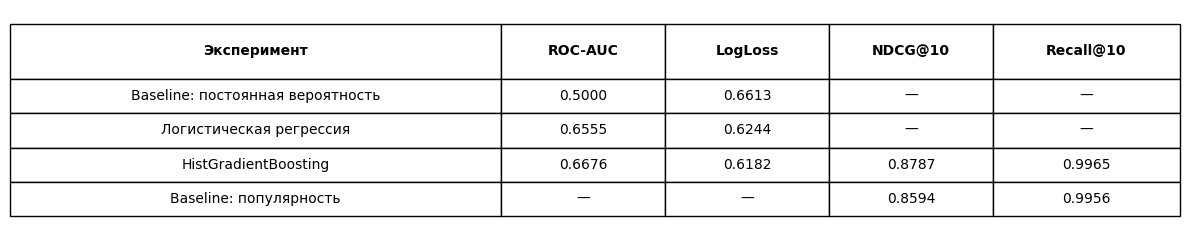

SVG сохранён как experiment_results.svg


In [31]:

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(12, 2.5))
ax.axis("off")

table_data = [
    ["Baseline: постоянная вероятность", "0.5000", "0.6613", "—", "—"],
    ["Логистическая регрессия", "0.6555", "0.6244", "—", "—"],
    ["HistGradientBoosting", "0.6676", "0.6182", "0.8787", "0.9965"],
    ["Baseline: популярность", "—", "—", "0.8594", "0.9956"],
]

columns = ["Эксперимент", "ROC-AUC", "LogLoss", "NDCG@10", "Recall@10"]

table = ax.table(
    cellText=table_data,
    colLabels=columns,
    cellLoc="center",
    colLoc="center",
    loc="center",
    colWidths=[0.42, 0.14, 0.14, 0.14, 0.16],
)

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(1, 1.8)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")
        cell.set_height(0.25)

plt.tight_layout()
plt.savefig("experiment_results.svg", format="svg", bbox_inches="tight")
plt.show()

print("SVG сохранён как experiment_results.svg")


In [32]:
# Проверяем, какие данные и модели доступны после предыдущих экспериментов

print("Переменные для проверки:")

for name in ["history", "train_new", "test_new", "test",
             "model", "lr_model", "test_df", "eval_df"]:
    if name in globals():
        obj = globals()[name]
        try:
            print(f"{name}: {obj.shape}")
        except AttributeError:
            print(f"{name}: существует, тип {type(obj).__name__}")
    else:
        print(f"{name}: не найдена")

Переменные для проверки:
history: (956711, 6)
train_new: (318904, 6)
test_new: (318904, 6)
test: (318958, 6)
model: существует, тип HistGradientBoostingClassifier
lr_model: существует, тип Pipeline
test_df: не найдена
eval_df: (318904, 4)


In [33]:
print("Столбцы eval_df:")
print(eval_df.columns.tolist())

print("\nПервые 5 строк:")
display(eval_df.head())

print("\nСтолбцы тестовой выборки:")
print(test_new.columns.tolist())

print("\nПервые 5 строк теста:")
display(test_new.head())

Столбцы eval_df:
['user_id', 'item_id', 'target', 'score']

Первые 5 строк:


,user_id,item_id,target,score
1275615,618408,8346,0,0.307465
1275616,84590,8437,0,0.492347
1275617,185259,15652,0,0.245366
1275618,566491,9728,1,0.524218
1275619,158506,1264,1,0.567543



Столбцы тестовой выборки:
['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct', 'target']

Первые 5 строк теста:


,user_id,item_id,last_watch_dt,total_dur,watched_pct,target
1275615,618408,8346,2021-08-04,12181.0,25.0,0
1275616,84590,8437,2021-08-04,1712.0,24.0,0
1275617,185259,15652,2021-08-04,460.0,8.0,0
1275618,566491,9728,2021-08-04,6269.0,92.0,1
1275619,158506,1264,2021-08-04,257.0,58.0,1


In [34]:
import pandas as pd
import numpy as np

# Сколько тестовых взаимодействий приходится на пользователя
user_stats = test_new.groupby("user_id")["target"].agg(
    interactions="count",
    positives="sum"
)

print("Всего пользователей в тесте:", len(user_stats))
print("Пользователей с 2+ фильмами:", (user_stats["interactions"] >= 2).sum())
print("Пользователей с 5+ фильмами:", (user_stats["interactions"] >= 5).sum())
print("Пользователей с 10+ фильмами:", (user_stats["interactions"] >= 10).sum())
print("Пользователей с 2+ фильмами и хотя бы одним положительным:",
      ((user_stats["interactions"] >= 2) &
       (user_stats["positives"] >= 1)).sum())

print("\nРаспределение числа фильмов на пользователя:")
print(user_stats["interactions"].describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
).round(2))

Всего пользователей в тесте: 167761
Пользователей с 2+ фильмами: 65151
Пользователей с 5+ фильмами: 11027
Пользователей с 10+ фильмами: 1610
Пользователей с 2+ фильмами и хотя бы одним положительным: 42487

Распределение числа фильмов на пользователя:
count    167761.00
mean          1.90
std           1.86
min           1.00
50%           1.00
75%           2.00
90%           4.00
95%           5.00
99%           9.00
max          81.00
Name: interactions, dtype: float64


In [35]:
import numpy as np
import pandas as pd

# 1. Оставляем фильмы, которые встречались в истории
known_items = set(history["item_id"].unique())

rank_df = eval_df[eval_df["item_id"].isin(known_items)].copy()

# 2. Считаем популярность исключительно по историческим данным
popularity = history.groupby("item_id")["target"].mean()

rank_df["popularity_score"] = (
    rank_df["item_id"].map(popularity).fillna(0)
)

# 3. Выбираем пользователей с более содержательным тестом
user_stats = rank_df.groupby("user_id")["target"].agg(
    interactions="count",
    positives="sum"
)

eligible_users = user_stats[
    (user_stats["interactions"] >= 5) &
    (user_stats["positives"] >= 1)
].index

rank_df = rank_df[rank_df["user_id"].isin(eligible_users)].copy()

print("Пользователей для оценки:", rank_df["user_id"].nunique())
print("Тестовых взаимодействий:", len(rank_df))

# 4. Расчёт NDCG@10 и Recall@10 по каждому пользователю
def ranking_metrics(df, score_col, k=10):
    ndcg_values = []
    recall_values = []

    for _, group in df.groupby("user_id"):
        group = group.sort_values(score_col, ascending=False)
        relevant = group["target"].to_numpy()

        top_relevant = relevant[:k]
        discounts = 1 / np.log2(np.arange(2, len(top_relevant) + 2))

        dcg = np.sum(top_relevant * discounts)

        ideal = np.sort(relevant)[::-1][:k]
        ideal_discounts = 1 / np.log2(np.arange(2, len(ideal) + 2))
        idcg = np.sum(ideal * ideal_discounts)

        total_relevant = relevant.sum()

        if idcg > 0:
            ndcg_values.append(dcg / idcg)

        if total_relevant > 0:
            recall_values.append(top_relevant.sum() / total_relevant)

    return {
        "NDCG@10": np.mean(ndcg_values),
        "Recall@10": np.mean(recall_values),
        "Пользователей": len(ndcg_values)
    }

results_rank = pd.DataFrame([
    {
        "Модель": "HistGradientBoosting",
        **ranking_metrics(rank_df, "score")
    },
    {
        "Модель": "Популярность",
        **ranking_metrics(rank_df, "popularity_score")
    }
])

display(results_rank.round(4))

Пользователей для оценки: 7691
Тестовых взаимодействий: 55029


,Модель,NDCG@10,Recall@10,Пользователей
0,HistGradientBoosting,0.8150,0.9825,7691
1,Популярность,0.8081,0.9827,7691


In [36]:
results_rank.to_csv(
    "ranking_results.csv",
    index=False
)

print("Сохранено: ranking_results.csv")

Сохранено: ranking_results.csv


In [37]:
print("Количество признаков модели:", model.n_features_in_)

print("\nНазвания признаков:")
print(getattr(model, "feature_names_in_", "Названия не сохранены"))

print("\nДоступные таблицы с признаками:")
for name in [
    "X_train", "X_test", "X_train_new", "X_test_new",
    "X_train_model", "X_test_model",
    "features_train", "features_test"
]:
    if name in globals():
        obj = globals()[name]
        print(
            name,
            "| тип:", type(obj).__name__,
            "| размер:", getattr(obj, "shape", "не таблица")
        )

Количество признаков модели: 4

Названия признаков:
['user_interactions' 'user_positive_rate' 'item_interactions'
 'item_positive_rate']

Доступные таблицы с признаками:
X_train | тип: DataFrame | размер: (1275828, 4)
X_test | тип: DataFrame | размер: (318958, 4)
X_train_new | тип: DataFrame | размер: (318904, 4)
X_test_new | тип: DataFrame | размер: (318904, 4)


In [38]:
import numpy as np
import pandas as pd

rng = np.random.default_rng(42)
K = 10
N_NEGATIVES = 100

# Исторические признаки пользователей и фильмов
user_agg = history.groupby("user_id")["target"].agg(
    user_interactions="count",
    user_positive_rate="mean"
)

item_agg = history.groupby("item_id")["target"].agg(
    item_interactions="count",
    item_positive_rate="mean"
)

global_rate = history["target"].mean()
catalog = np.array(item_agg.index)

# Оставляем фильмы теста, известные по истории
test_known = test_new[
    test_new["item_id"].isin(catalog)
][["user_id", "item_id", "target"]].copy()

# Одна строка на пару пользователь-фильм
test_known = test_known.groupby(
    ["user_id", "item_id"], as_index=False
)["target"].max()

stats = test_known.groupby("user_id")["target"].agg(
    interactions="count",
    positives="sum"
)

eligible = stats[
    (stats["interactions"] >= 5) &
    (stats["positives"] >= 1)
].index

test_known = test_known[
    test_known["user_id"].isin(eligible)
].copy()

print("Пользователей:", test_known["user_id"].nunique())
print("Тестовых пар:", len(test_known))

# Для каждого пользователя добавляем случайные альтернативы
known_by_user = test_known.groupby("user_id")["item_id"].agg(set)
candidate_parts = [test_known]

for user_id in known_by_user.index:
    excluded = known_by_user[user_id]
    available = np.array([i for i in catalog if i not in excluded])

    if len(available) == 0:
        continue

    sample_size = min(N_NEGATIVES, len(available))
    sampled = rng.choice(available, size=sample_size, replace=False)

    candidate_parts.append(pd.DataFrame({
        "user_id": user_id,
        "item_id": sampled,
        "target": 0
    }))

candidates = pd.concat(candidate_parts, ignore_index=True)

# Добавляем признаки, построенные только по историческим данным
candidates = candidates.join(user_agg, on="user_id")
candidates = candidates.join(item_agg, on="item_id")

candidates["user_interactions"] = (
    candidates["user_interactions"].fillna(0)
)
candidates["user_positive_rate"] = (
    candidates["user_positive_rate"].fillna(global_rate)
)
candidates["item_interactions"] = (
    candidates["item_interactions"].fillna(0)
)
candidates["item_positive_rate"] = (
    candidates["item_positive_rate"].fillna(global_rate)
)

feature_cols = [
    "user_interactions",
    "user_positive_rate",
    "item_interactions",
    "item_positive_rate"
]

# Получаем предсказания для всех кандидатов
candidates["score"] = model.predict_proba(
    candidates[feature_cols]
)[:, 1]

# Считаем NDCG@10 и Recall@10 по кандидатам
def sampled_ranking_metrics(df, score_col, k=10):
    ndcg_values = []
    recall_values = []

    for _, group in df.groupby("user_id"):
        labels = group["target"].to_numpy()
        scores = group[score_col].to_numpy()

        order = np.argsort(-scores)
        ranked_labels = labels[order][:k]

        discounts = 1 / np.log2(np.arange(2, len(ranked_labels) + 2))
        dcg = np.sum(ranked_labels * discounts)

        ideal = np.sort(labels)[::-1][:k]
        ideal_discounts = 1 / np.log2(np.arange(2, len(ideal) + 2))
        idcg = np.sum(ideal * ideal_discounts)

        total_positive = labels.sum()

        if idcg > 0 and total_positive > 0:
            ndcg_values.append(dcg / idcg)
            recall_values.append(ranked_labels.sum() / total_positive)

    return {
        "NDCG@10": np.mean(ndcg_values) if ndcg_values else np.nan,
        "Recall@10": np.mean(recall_values) if recall_values else np.nan,
        "Пользователей": len(ndcg_values)
    }

sampled_results = pd.DataFrame([{
    "Модель": "HistGradientBoosting",
    **sampled_ranking_metrics(candidates, "score", K)
}])

display(sampled_results.round(4))

sampled_results.to_csv("sampled_ranking_results.csv", index=False)
print("Сохранено: sampled_ranking_results.csv")

Пользователей: 7691
Тестовых пар: 55029


,Модель,NDCG@10,Recall@10,Пользователей
0,HistGradientBoosting,0.0593,0.0774,7691


Сохранено: sampled_ranking_results.csv


In [39]:
# Контрольный baseline на ТОЧНО ТОМ ЖЕ наборе кандидатов

candidates["popularity_score"] = (
    candidates["item_positive_rate"]
)

baseline_result = {
    "Модель": "Популярность",
    **sampled_ranking_metrics(candidates, "popularity_score", 10)
}

comparison = pd.concat([
    sampled_results,
    pd.DataFrame([baseline_result])
], ignore_index=True)

display(comparison.round(4))

comparison.to_csv(
    "sampled_ranking_comparison.csv",
    index=False
)

print("Сохранено: sampled_ranking_comparison.csv")

,Модель,NDCG@10,Recall@10,Пользователей
0,HistGradientBoosting,0.0593,0.0774,7691
1,Популярность,0.0087,0.0070,7691


Сохранено: sampled_ranking_comparison.csv


In [40]:
# Случайный baseline на том же наборе кандидатов
rng = np.random.default_rng(42)

candidates["random_score"] = rng.random(len(candidates))

random_result = {
    "Модель": "Случайное ранжирование",
    **sampled_ranking_metrics(candidates, "random_score", 10)
}

final_comparison = pd.concat(
    [comparison, pd.DataFrame([random_result])],
    ignore_index=True
)

display(final_comparison.round(4))

final_comparison.to_csv(
    "final_ranking_comparison.csv",
    index=False
)

print("Сохранено: final_ranking_comparison.csv")

,Модель,NDCG@10,Recall@10,Пользователей
0,HistGradientBoosting,0.0593,0.0774,7691
1,Популярность,0.0087,0.0070,7691
2,Случайное ранжирование,0.0608,0.0933,7691


Сохранено: final_ranking_comparison.csv


In [41]:
print("history:", "history" in globals())
print("train_new:", "train_new" in globals())
print("test_new:", "test_new" in globals())
print("HistGradientBoosting:", "model" in globals())

history: True
train_new: True
test_new: True
HistGradientBoosting: True


In [42]:
print("Столбцы history:", history.columns.tolist())
print("Столбцы train_new:", train_new.columns.tolist())
print("Столбцы test_new:", test_new.columns.tolist())

print("\nПериод истории:")
print(history["last_watch_dt"].min(), "—", history["last_watch_dt"].max())

print("\nРазмер истории:", history.shape)
print("Размер обучения:", train_new.shape)
print("Размер теста:", test_new.shape)

Столбцы history: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct', 'target']
Столбцы train_new: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct', 'target']
Столбцы test_new: ['user_id', 'item_id', 'last_watch_dt', 'total_dur', 'watched_pct', 'target']

Период истории:
2021-03-13 00:00:00 — 2021-07-13 00:00:00

Размер истории: (956711, 6)
Размер обучения: (318904, 6)
Размер теста: (318904, 6)


In [43]:
for name, df in [
    ("История", history),
    ("Обучение", train_new),
    ("Тест", test_new),
]:
    print(
        f"{name}: "
        f"{df['last_watch_dt'].min()} — "
        f"{df['last_watch_dt'].max()}"
    )

История: 2021-03-13 00:00:00 — 2021-07-13 00:00:00
Обучение: 2021-07-13 00:00:00 — 2021-08-04 00:00:00
Тест: 2021-08-04 00:00:00 — 2021-08-22 00:00:00


In [44]:
print("Последняя дата истории:", history["last_watch_dt"].max())
print("Строк в истории:", len(history))
print("Положительная доля в истории:", round(history["target"].mean(), 4))
print("Пропуски дат:", history["last_watch_dt"].isna().sum())

Последняя дата истории: 2021-07-13 00:00:00
Строк в истории: 956711
Положительная доля в истории: 0.476
Пропуски дат: 0


In [45]:
import pandas as pd

hist = history.copy()
hist["last_watch_dt"] = pd.to_datetime(hist["last_watch_dt"])

max_date = hist["last_watch_dt"].max()

for days in [7, 30, 60]:
    recent = hist[
        hist["last_watch_dt"] >= max_date - pd.Timedelta(days=days)
    ]

    print(f"\nОкно {days} дней")
    print("Строк:", len(recent))
    print("Пользователей:", recent["user_id"].nunique())
    print("Фильмов:", recent["item_id"].nunique())
    print("Доля положительных:", round(recent["target"].mean(), 4))


Окно 7 дней
Строк: 88158
Пользователей: 59729
Фильмов: 4924
Доля положительных: 0.4917

Окно 30 дней
Строк: 392490
Пользователей: 199776
Фильмов: 7256
Доля положительных: 0.5141

Окно 60 дней
Строк: 638471
Пользователей: 282652
Фильмов: 8709
Доля положительных: 0.4865


In [46]:
print("Признаки:", X_train_new.columns.tolist()
      if hasattr(X_train_new, "columns")
      else getattr(X_train_new, "shape", "нет X_train_new"))

print("\nМодель:")
print(model)

Признаки: ['user_interactions', 'user_positive_rate', 'item_interactions', 'item_positive_rate']

Модель:
HistGradientBoostingClassifier(max_leaf_nodes=15, random_state=42)


In [47]:
import pandas as pd

hist = history.copy()
hist["last_watch_dt"] = pd.to_datetime(hist["last_watch_dt"])

cutoff = hist["last_watch_dt"].max()

for days in [7, 30, 60]:
    recent = hist[
        hist["last_watch_dt"] >= cutoff - pd.Timedelta(days=days)
    ]

    user_stats = recent.groupby("user_id").agg(
        **{
            f"user_interactions_{days}d": ("target", "size"),
            f"user_positive_rate_{days}d": ("target", "mean"),
        }
    )

    item_stats = recent.groupby("item_id").agg(
        **{
            f"item_interactions_{days}d": ("target", "size"),
            f"item_positive_rate_{days}d": ("target", "mean"),
        }
    )

    print(
        f"{days} дней: "
        f"пользовательских групп — {len(user_stats)}, "
        f"групп фильмов — {len(item_stats)}"
    )

7 дней: пользовательских групп — 59729, групп фильмов — 4924
30 дней: пользовательских групп — 199776, групп фильмов — 7256
60 дней: пользовательских групп — 282652, групп фильмов — 8709


In [48]:
import pandas as pd
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import roc_auc_score, log_loss

hist = history.copy()
hist["last_watch_dt"] = pd.to_datetime(hist["last_watch_dt"])
cutoff = hist["last_watch_dt"].max()

# Базовые признаки
base_features = [
    "user_interactions",
    "user_positive_rate",
    "item_interactions",
    "item_positive_rate"
]

# Создаём временные признаки только по history
extra_train = X_train_new.copy()
extra_test = X_test_new.copy()

for days in [7, 30, 60]:
    recent = hist[
        hist["last_watch_dt"] >= cutoff - pd.Timedelta(days=days)
    ]

    user_stats = recent.groupby("user_id")["target"].agg(
        ["count", "mean"]
    )
    item_stats = recent.groupby("item_id")["target"].agg(
        ["count", "mean"]
    )

    user_stats.columns = [
        f"user_interactions_{days}d",
        f"user_positive_rate_{days}d"
    ]
    item_stats.columns = [
        f"item_interactions_{days}d",
        f"item_positive_rate_{days}d"
    ]

    # Используем индексы объектов в X, если они сохранены.
    # Если X_train_new не содержит user_id/item_id,
    # нужно присоединить статистики к train_new/test_new.
    train_ids = train_new[["user_id", "item_id"]]
    test_ids = test_new[["user_id", "item_id"]]

    for col in user_stats.columns:
        extra_train[col] = train_ids["user_id"].map(user_stats[col]).fillna(0).to_numpy()
        extra_test[col] = test_ids["user_id"].map(user_stats[col]).fillna(0).to_numpy()

    for col in item_stats.columns:
        extra_train[col] = train_ids["item_id"].map(item_stats[col]).fillna(0).to_numpy()
        extra_test[col] = test_ids["item_id"].map(item_stats[col]).fillna(0).to_numpy()

# Сравниваем базовую модель и расширенную
y_train = train_new["target"]
y_test = test_new["target"]

results = []

for name, Xtr, Xte in [
    ("Базовая модель", X_train_new[base_features], X_test_new[base_features]),
    ("Временные признаки", extra_train, extra_test)
]:
    clf = HistGradientBoostingClassifier(
        max_iter=100,
        max_leaf_nodes=15,
        learning_rate=0.1,
        random_state=42
    )
    clf.fit(Xtr, y_train)
    pred = clf.predict_proba(Xte)[:, 1]

    results.append({
        "Модель": name,
        "ROC-AUC": roc_auc_score(y_test, pred),
        "LogLoss": log_loss(y_test, pred)
    })

results_df = pd.DataFrame(results)
display(results_df)

,Модель,ROC-AUC,LogLoss
0,Базовая модель,0.667646,0.618229
1,Временные признаки,0.668534,0.618664


In [49]:
results_df.to_csv("feature_experiment_results.csv", index=False)

print("Результаты сохранены.")
display(results_df)

Результаты сохранены.


,Модель,ROC-AUC,LogLoss
0,Базовая модель,0.667646,0.618229
1,Временные признаки,0.668534,0.618664


In [50]:
# Проверяем, сколько пар пользователь–фильм повторяется в истории
pair_counts = (
    history.groupby(["user_id", "item_id"])
    .size()
)

print("Всего пар пользователь–фильм:", len(pair_counts))
print("Повторных пар:", (pair_counts > 1).sum())
print("Доля повторных пар:", round((pair_counts > 1).mean(), 4))

Всего пар пользователь–фильм: 956711
Повторных пар: 0
Доля повторных пар: 0.0


In [51]:
history_users = set(history["user_id"].unique())

test_users = test_new["user_id"]
new_user_mask = ~test_users.isin(history_users)

print("Всего тестовых взаимодействий:", len(test_new))
print("Взаимодействий новых пользователей:", new_user_mask.sum())
print(
    "Доля взаимодействий новых пользователей:",
    round(new_user_mask.mean() * 100, 2), "%"
)
print(
    "Уникальных новых пользователей:",
    test_new.loc[new_user_mask, "user_id"].nunique()
)

Всего тестовых взаимодействий: 318904
Взаимодействий новых пользователей: 219483
Доля взаимодействий новых пользователей: 68.82 %
Уникальных новых пользователей: 119147


In [52]:
from sklearn.metrics import roc_auc_score, log_loss
import pandas as pd

history_users = set(history["user_id"].unique())
new_mask = ~test_new["user_id"].isin(history_users)

pred = model.predict_proba(X_test_new)[:, 1]
y = test_new["target"].to_numpy()

rows = []

for name, mask in [
    ("Знакомые пользователи", ~new_mask.to_numpy()),
    ("Новые пользователи", new_mask.to_numpy())
]:
    mask = pd.Series(mask).to_numpy()
    y_part = y[mask]
    p_part = pred[mask]

    rows.append({
        "Группа": name,
        "Взаимодействий": int(mask.sum()),
        "Доля положительных": round(float(y_part.mean()), 4),
        "ROC-AUC": (
            round(float(roc_auc_score(y_part, p_part)), 4)
            if len(set(y_part)) > 1 else None
        ),
        "LogLoss модели": round(float(log_loss(y_part, p_part)), 4),
        "LogLoss константы": round(
            float(log_loss(y_part, [y.mean()] * len(y_part))), 4
        )
    })

display(pd.DataFrame(rows))

,Группа,Взаимодействий,Доля положительных,ROC-AUC,LogLoss модели,LogLoss константы
0,Знакомые пользователи,99421,0.3884,0.5829,2.3381,0.6692
1,Новые пользователи,219483,0.3535,0.6544,2.5359,0.6498
